In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from scipy.integrate import quad

plt.style.use(['science'])

# Constants
c = 299792.458   # km / s
H0 = 67       # km / s / Mpc
fv0 = 0.695
Omm = 0.315

In [2]:
def H_bar_0(fv0, H_0):
    return 2 * (2 + fv0) * H_0 / (4 *fv0**2 + fv0 + 4)


def Hubble(z, Omega_m=Omm):
    return H0 * np.sqrt(Omega_m * (1 + z)**3 + (1 - Omega_m))


def comoving_distance(z, H0, Omega_m=Omm): 
    integrand = lambda z: c / Hubble(z, Omega_m)
    distance, _ = quad(integrand, 0, z)
    return distance


def angular_diameter_distance_lcdm(z, H0, Omega_m=Omm):
    d_c = comoving_distance(z, H0, Omega_m)
    return d_c / (1 + z)


def b(fv0, H_0):
    output = 2 * (1 - fv0) * (2 + fv0) / (9 * fv0 * H_bar_0(fv0, H_0))
    return output


def F(t, fv0, H_0):
    term1 = 2 * t ** (1/3)
    term2 = b(fv0, H_0)**(1/3) / 6 * np.log( (t**(1/3) + b(fv0, H_0)**(1/3))**2 / (t **(2/3) - b(fv0, H_0)**(1/3) * t**(1/3) + b(fv0, H_0)**(2/3)) )
    term3 = b(fv0, H_0)**(1/3) / np.sqrt(3) * np.arctan( (2 * t**(1/3) - b(fv0, H_0)**(1/3)) / (np.sqrt(3) * b(fv0, H_0)**(1/3)) )
    return term1 + term2 + term3


def angular_diameter_distance(t, t0, fv0, H_0):
    return c * t ** (2 / 3) * (F(t0, fv0, H_0) - F(t, fv0, H_0))

def z_of_t(t, fv0, H_0):
    return 2**(4/3) * t ** (1/3) * (t + b(fv0, H_0)) / (fv0 **(1/3) * H_bar_0(fv0, H_0)* t * (2*t+3*b(fv0, H_0))**(4/3)) -1

In [3]:
t_present = (2 + fv0) / (3*H_bar_0(fv0, H0))

print("Present time t0:", t_present)
z_of_t(t_present,fv0,H0)

Present time t0: 0.016485323383084574


2.220446049250313e-16

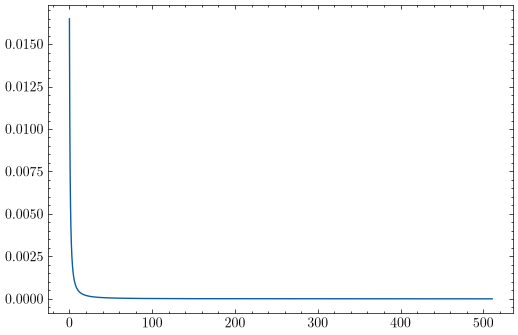

In [4]:
tt = np.geomspace(1e-4 * t_present, t_present, 1000)

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(z_of_t(tt, fv0, H0), tt)
# ax.vlines(t_present, 0, 120, color='r', linestyle='--', label='Present time')

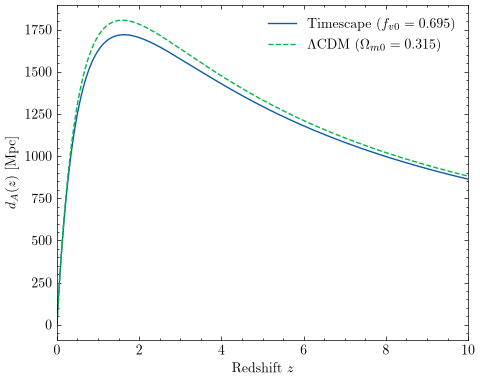

In [5]:

tt = np.geomspace(1e-4 * t_present, t_present, 1000)
z_ts = z_of_t(tt, fv0, H0)
dA_ts = angular_diameter_distance(tt, t_present, fv0, H0)  # In Mpc

dA_lcdm_vals = [angular_diameter_distance_lcdm(z, H0, Omm) for z in z_ts]

# 3. Plot d_A(z) for z in [0, 10] and the full range up to z ~ 120
fig, ax1 = plt.subplots(figsize=(5, 4))

# Left panel: Low-to-intermediate redshift (shows the turnaround peak at z ~ 1.6)
ax1.plot(z_ts, dA_ts, label=f'Timescape ($f_{{v0}}={fv0}$)')
ax1.plot(z_ts, dA_lcdm_vals, '--', label=f'$\\Lambda$CDM ($\\Omega_{{m0}}={Omm}$)')
ax1.set_xlim(0, 10)
ax1.set_xlabel('Redshift $z$')
ax1.set_ylabel('$d_A(z)$ [Mpc]')
ax1.legend()

fig.savefig('../imgs/DA.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

In [6]:
t_near = 0.9999 * t_present
print("Effective H0 at z->0:", c * z_of_t(t_near, fv0, H0) / angular_diameter_distance(t_near, t_present, fv0, H0))

Effective H0 at z->0: 67.00762713653093


/var/folders/0n/67m69hyn6679b2j6j3zmrq4c0000gp/T/ipykernel_28880/4160662058.py:36: RuntimeWarning: invalid value encountered in power
  return 2**(4/3) * t ** (1/3) * (t + b(fv0, H_0)) / (fv0 **(1/3) * H_bar_0(fv0, H_0)* t * (2*t+3*b(fv0, H_0))**(4/3)) -1
/var/folders/0n/67m69hyn6679b2j6j3zmrq4c0000gp/T/ipykernel_28880/4160662058.py:27: RuntimeWarning: invalid value encountered in scalar power
  term2 = b(fv0, H_0)**(1/3) / 6 * np.log( (t**(1/3) + b(fv0, H_0)**(1/3))**2 / (t **(2/3) - b(fv0, H_0)**(1/3) * t**(1/3) + b(fv0, H_0)**(2/3)) )
/var/folders/0n/67m69hyn6679b2j6j3zmrq4c0000gp/T/ipykernel_28880/4160662058.py:28: RuntimeWarning: invalid value encountered in scalar power
  term3 = b(fv0, H_0)**(1/3) / np.sqrt(3) * np.arctan( (2 * t**(1/3) - b(fv0, H_0)**(1/3)) / (np.sqrt(3) * b(fv0, H_0)**(1/3)) )


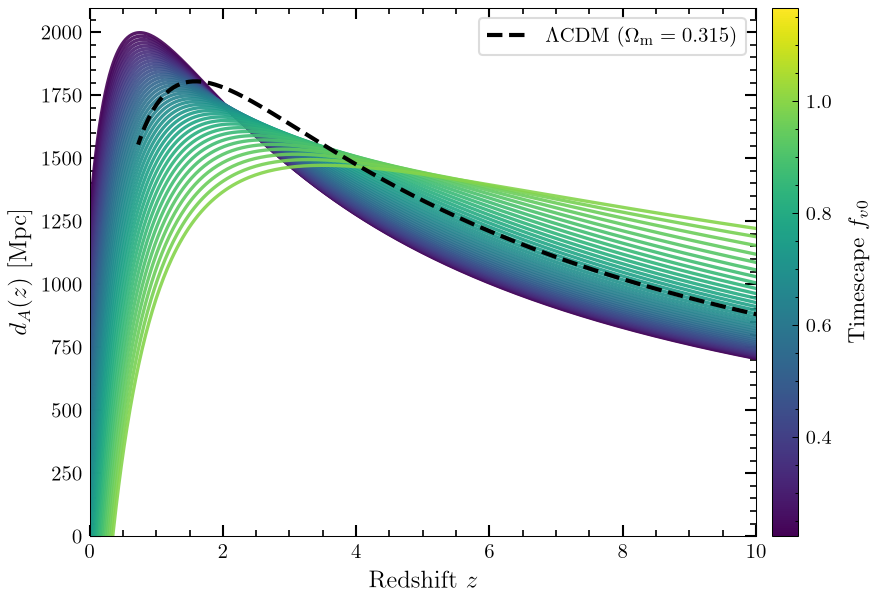

In [8]:
import matplotlib as mpl
from matplotlib.ticker import AutoMinorLocator
fv0 = 0.695
# 1. Sample volume-average time t from early universe up to t_present
# Using logspace gives smooth resolution across both low z and high z (up to z ~ 120)
tt = np.geomspace(1e-4 * t_present, t_present, 1000)
fv0_vals = np.linspace(fv0*0.32, fv0*1.68, 50)

fig, ax1 = plt.subplots(figsize=(6.2, 4.2), dpi=150)

cmap = plt.cm.viridis
norm = mpl.colors.Normalize(vmin=fv0_vals.min(), vmax=fv0_vals.max())

for fv0 in fv0_vals:
    z_ts = z_of_t(tt, fv0, H0)
    dA_ts = angular_diameter_distance(tt, t_present, fv0, H0)  # In Mpc

    # 2. Compute Flat LCDM angular diameter distance for comparison (Omega_m0 = 0.315)
    Omega_m0 = 0.315
    def dA_lcdm(z_array, H0, Omega_m0):
        dA_list = []
        for z in z_array:
            integrand = lambda zp: 1.0 / np.sqrt(Omega_m0 * (1 + zp)**3 + (1 - Omega_m0))
            dc, _ = quad(integrand, 0, z)
            dA_list.append((c / H0) * dc / (1 + z))
        return np.array(dA_list)

    dA_lcdm_vals = dA_lcdm(z_ts, H0, Omega_m0)

    # 3. Plot d_A(z) for z in [0, 10] and the full range up to z ~ 120

    # Left panel: Low-to-intermediate redshift (shows the turnaround peak at z ~ 1.6)
    ax1.plot(z_ts, dA_ts, color=cmap(norm(fv0)), lw=1.6, alpha=0.9)

ax1.plot(z_ts, dA_lcdm_vals, color='black', ls='--', lw=2.0, zorder=10,
         label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omega_m0}$)')

# Colorbar for Timescape f_v0 values
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1, pad=0.02)
cbar.set_label(r'Timescape $f_{v0}$', fontsize=11, labelpad=8)
cbar.ax.tick_params(labelsize=9.5)

# Axes limits, labels, ticks, and grid
ax1.set_xlim(0, 10)
ax1.set_ylim(bottom=0)
ax1.set_xlabel('Redshift $z$', fontsize=12)
ax1.set_ylabel('$d_A(z)$ [Mpc]', fontsize=12)

ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(which='both', direction='in', top=True, right=True, labelsize=10)
ax1.tick_params(which='major', length=5.5, width=1.0)
ax1.tick_params(which='minor', length=3.0, width=0.8)

# ax1.grid(True, which='major', ls=':', lw=0.7, alpha=0.45)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', fontsize=10, loc='upper right')

# fig.savefig('../imgs/DA.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()
